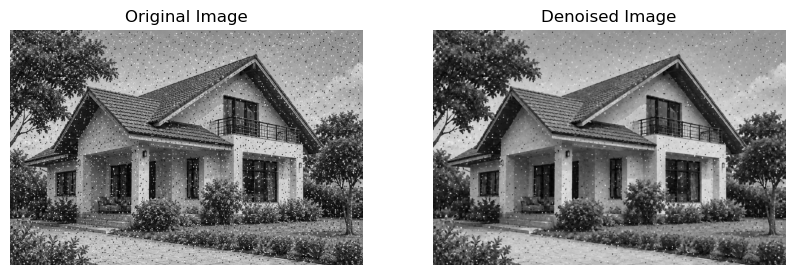

Image Processing Completed!
Output saved as output.jpg


In [2]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Step 1: Load grayscale image
img = Image.open("input.png").convert("L")
image = np.array(img)

# Step 2: Initialize parameters
ITERATIONS = 10
GRID_SIZE = 3

# Step 3: Fitness function
def fitness(pixel, neighbors):
    return abs(int(pixel) - int(np.median(neighbors)))

# Step 4: Cellular update
for iteration in range(ITERATIONS):

    padded = np.pad(image, 1, mode='edge')

    # Get 3x3 neighborhood
    neighbors = []

    for i in range(GRID_SIZE):
        for j in range(GRID_SIZE):
            neighbors.append(
                padded[i:i+image.shape[0],
                       j:j+image.shape[1]]
            )

    # Calculate median for every pixel
    new_image = np.median(
        np.stack(neighbors), axis=0
    ).astype(np.uint8)

    # Update all cells simultaneously
    image = new_image

# Step 5: Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image, cmap='gray')
plt.title("Denoised Image")
plt.axis("off")

plt.show()

# Step 6: Save output
Image.fromarray(image).save("output.jpg")

print("Image Processing Completed!")
print("Output saved as output.jpg")

